In [ ]:
import os
import time
import mirtorch 
from mirtorch.linear import Identity, Diff3dgram, NuSense, NuSenseGram
from mirtorch.alg import CG, power_iter, POGM
from mirtorch.prox import Const, L1Regularizer
import torch
from RawData import *
from obj.helpers import *
import numpy as np
import matplotlib.pyplot as plt
from FSLViewer import FSLViewer
from Smap import Smaps
import gc

In [2]:
viewer = FSLViewer()

device = best_available_device()
torch.manual_seed(0)
print(f"Using {device}")

smap = Smaps.load("/home/clouly/DEV/asldata/20260929/smaps/ball_smap.mat", cdim=-1).to(torch.complex64).to(device)#.compress(4)
viewer.add_smap(smap)
print(smap)

Using cuda
<Smaps Object: On cuda:0 with shape (32, 64, 64, 64). Currently NOT COMPRESSED>


In [3]:
y_B0_raw = [y.initial_clip().coil_compress(smap).capria_swap().set_mirt_shape() for y in RawData.from_dir("/home/clouly/DEV/asldata/20260929/asldata_te*_a20", verbose=True)]
TEs = torch.tensor([3.5, 5.4, 7.4, 10.5])

ktraj = torch.cat([y.traj for y in y_B0_raw], dim=0).to(device)
y_B0 = torch.cat([y.data for y in y_B0_raw], dim=0).to(device)

Working on '/home/clouly/DEV/asldata/20260929/asldata_te03_a20':
Working on '/home/clouly/DEV/asldata/20260929/asldata_te05_a20':
Working on '/home/clouly/DEV/asldata/20260929/asldata_te07_a20':
Working on '/home/clouly/DEV/asldata/20260929/asldata_te10_a20':


In [4]:
for y in y_B0_raw: print(y)
print(ktraj.shape)
print(y_B0.shape)

<RawData Object: On cpu with shape (1, 32, 113310)>
<RawData Object: On cpu with shape (1, 32, 113310)>
<RawData Object: On cpu with shape (1, 32, 113310)>
<RawData Object: On cpu with shape (1, 32, 113310)>
torch.Size([4, 3, 113310])
torch.Size([4, 32, 113310])


In [5]:
vt = list(ktraj.shape)
vt[1] = 1

w = torch.full(tuple(vt), 1.0, dtype=torch.complex64, device=ktraj.device)
fake_smap = torch.full(smap.shape[1:], 1.0, dtype=torch.complex64, device=ktraj.device)[None, None, ...]
Af = NuSense(fake_smap, ktraj).to(device)
ktraj = ktraj.to("cpu")

w, sn = power_iter(Af * Af.H, w, max_iter=10)
w = torch.real(w)
w /= torch.linalg.norm(w)

del Af
del fake_smap

w = w.to(device)

In [6]:
def hns(v):
    return 0.5 * (torch.linalg.norm(v).item() ** 2)

In [7]:
def init_scale(A, y, x0):
    # Find argmin_s 1/2 ||y - s A x0||_2^2
    Ax0 = A * x0
    s = (torch.sum(y.conj() * Ax0, dim=tuple(range(1,y.ndim))).conj() / (torch.sum(Ax0 * Ax0.conj(), dim=tuple(range(1,Ax0.ndim)))))
    return x0 * s[:, None, None, None, None]

In [8]:
ktraj = torch.as_tensor(ktraj, device=device)
A = NuSense(smap[None].get_tensor(), ktraj, sequential=True).to(device)
R = Identity(A.size_in).to(device)

print(A.size_in, A.size_out)

[4, 1, 64, 64, 64] [4, 32, 113310]


In [9]:
print("RECONNING --- B0")
max_iter=1000
cl_reg = 10**0

y = y_B0
y_nrm = torch.linalg.norm(y).item()


AHy = A.H * y.to(device)
x0 = A.H * (y.to(device) * w)
x0 = init_scale(A, y.to(device), x0)


x_B0, recon_time = timed(
    lambda: CG(
        (A.H * A) + cl_reg * R,
        alert=True,
        max_iter=max_iter,
        eval_func= lambda res: (torch.linalg.norm(res)).item(),
        rtol=10**-6
    ).run(x0, AHy, return_info=True),
    device
)


print("Recon Took:", recon_time)
print(torch.linalg.norm(AHy) ** 2)

RECONNING --- B0
Recon Took: 19.954012291505933
tensor(2.8915e+13, device='cuda:0')


Recon Took:  19.954012291505933
Control:     True 31 4.077105522155762


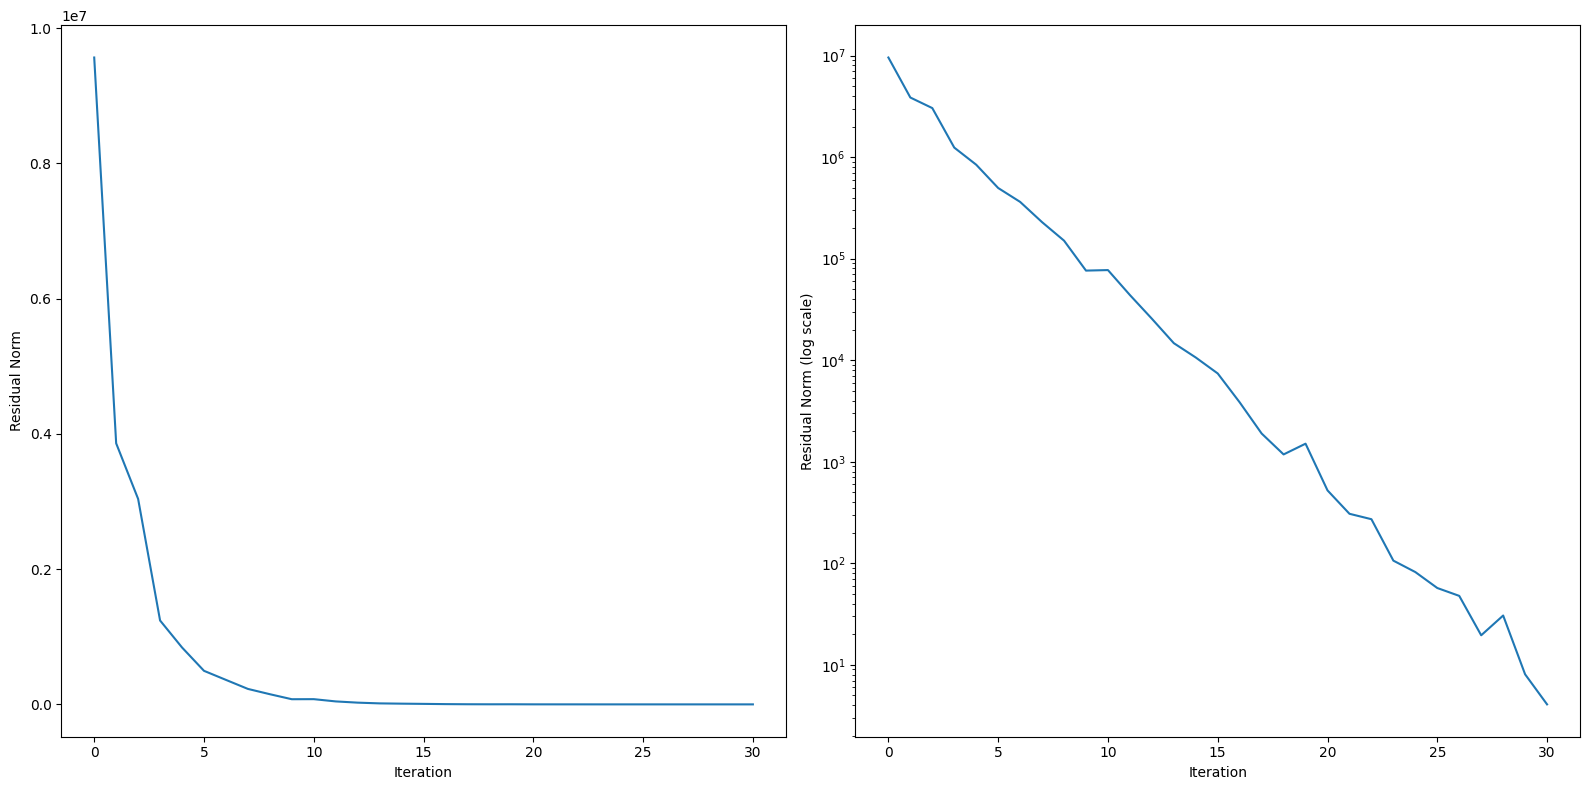

In [10]:
x_B0_img = x_B0.solution.squeeze(1)
viewer.add(torch.angle(x_B0_img), "B0_series_img_ang", tdim=0)
viewer.add(torch.abs(x_B0_img), "B0_series_img_mag", tdim=0)
print("Recon Took: ", recon_time)
print("Control:    ", x_B0.converged, x_B0.iterations, x_B0.residual_norm.item())

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 8))

ax[0].plot(x_B0.history)
ax[0].set_xlabel("Iteration")
ax[0].set_ylabel("Residual Norm")

ax[1].semilogy(x_B0.history)
ax[1].set_xlabel("Iteration")
ax[1].set_ylabel("Residual Norm (log scale)")

fig.tight_layout()
plt.show()

In [11]:
y_B1_raw = [y.initial_clip().coil_compress(smap).capria_swap().set_mirt_shape() for y in RawData.from_dir("/home/clouly/DEV/asldata/20260929/asldata_te03_a*", verbose=True)]
flips = torch.tensor([10.0, 20.0, 30.0, 40.0, 50.0, 70.0])

ktraj = torch.cat([y.traj for y in y_B1_raw], dim=0).to(device)
y_B1 = torch.cat([y.data for y in y_B1_raw], dim=0).to(device)

Working on '/home/clouly/DEV/asldata/20260929/asldata_te03_a10':
Working on '/home/clouly/DEV/asldata/20260929/asldata_te03_a20':
Working on '/home/clouly/DEV/asldata/20260929/asldata_te03_a30':
Working on '/home/clouly/DEV/asldata/20260929/asldata_te03_a40':
Working on '/home/clouly/DEV/asldata/20260929/asldata_te03_a50':
Working on '/home/clouly/DEV/asldata/20260929/asldata_te03_a70':


In [12]:
for y in y_B1_raw: print(y)
print(ktraj.shape)
print(y_B1.shape)

<RawData Object: On cpu with shape (1, 32, 113310)>
<RawData Object: On cpu with shape (1, 32, 113310)>
<RawData Object: On cpu with shape (1, 32, 113310)>
<RawData Object: On cpu with shape (1, 32, 113310)>
<RawData Object: On cpu with shape (1, 32, 113310)>
<RawData Object: On cpu with shape (1, 32, 113310)>
torch.Size([6, 3, 113310])
torch.Size([6, 32, 113310])


In [13]:
vt = list(ktraj.shape)
vt[1] = 1

w = torch.full(tuple(vt), 1.0, dtype=torch.complex64, device=ktraj.device)
fake_smap = torch.full(smap.shape[1:], 1.0, dtype=torch.complex64, device=ktraj.device)[None, None, ...]
Af = NuSense(fake_smap, ktraj).to(device)
ktraj = ktraj.to("cpu")

w, sn = power_iter(Af * Af.H, w, max_iter=10)
w = torch.real(w)
w /= torch.linalg.norm(w)

del Af
del fake_smap

w = w.to(device)

In [14]:
ktraj = torch.as_tensor(ktraj, device=device)
A = NuSense(smap[None].get_tensor(), ktraj, sequential=True).to(device)
R = Identity(A.size_in).to(device)

print(A.size_in, A.size_out)

[6, 1, 64, 64, 64] [6, 32, 113310]


In [15]:
print("RECONNING --- B1")
max_iter=1000
cl_reg = 10**0

y = y_B1
y_nrm = torch.linalg.norm(y).item()


AHy = A.H * y.to(device)
x0 = A.H * (y.to(device) * w)
x0 = init_scale(A, y.to(device), x0)


x_B1, recon_time = timed(
    lambda: CG(
        (A.H * A) + cl_reg * R,
        alert=True,
        max_iter=max_iter,
        eval_func= lambda res: (torch.linalg.norm(res)).item(),
        rtol=10**-6
    ).run(x0, AHy, return_info=True),
    device
)


print("Recon Took:", recon_time)
print(torch.linalg.norm(AHy) ** 2)

RECONNING --- B1
Recon Took: 29.879538290202618
tensor(8.1815e+13, device='cuda:0')


Recon Took:  29.879538290202618
Control:     True 31 6.867938995361328


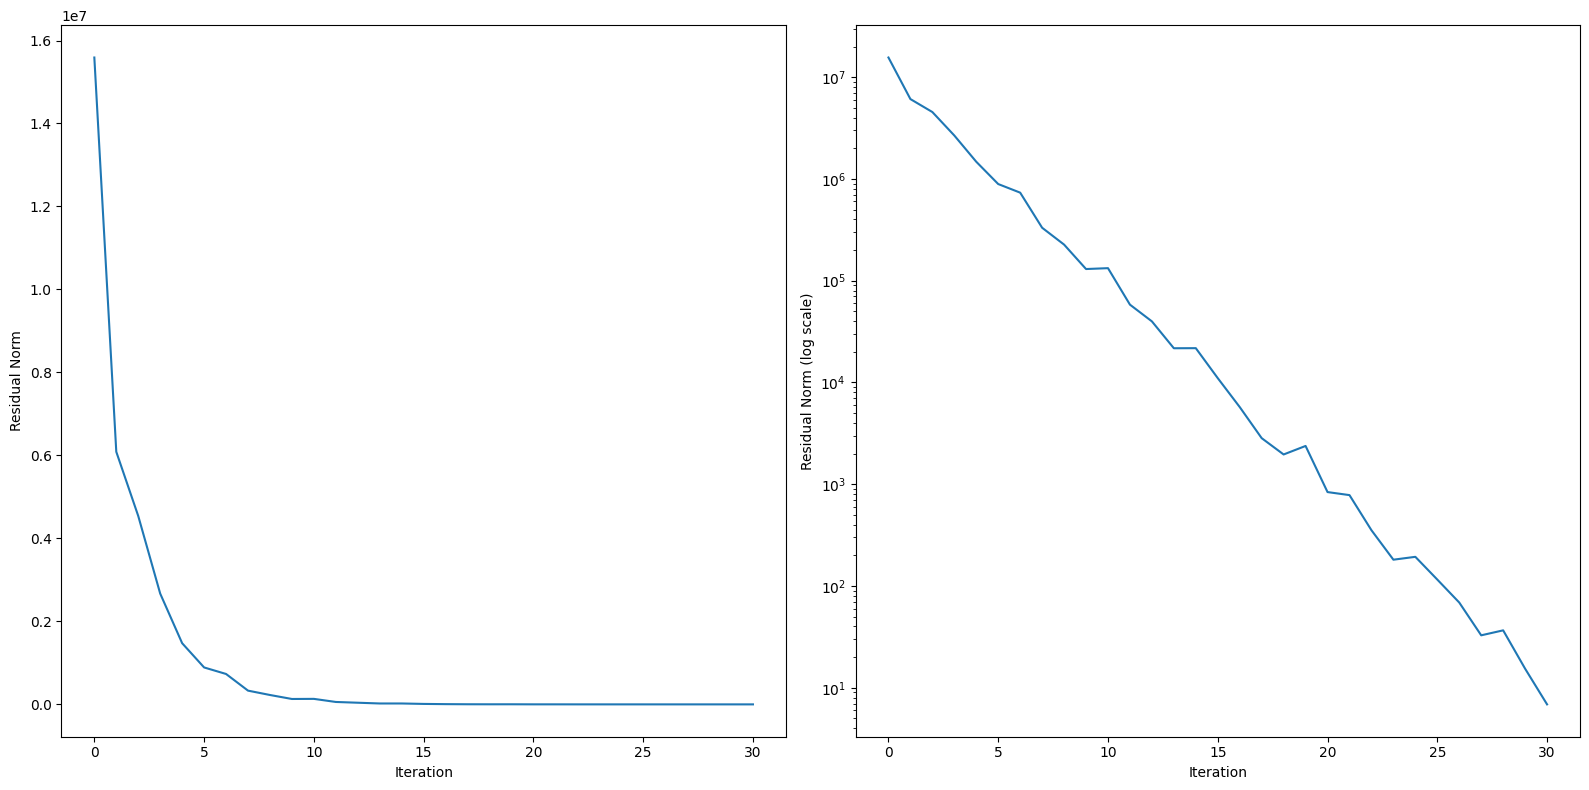

In [16]:
x_B1_img = x_B1.solution.squeeze(1)
viewer.add(torch.angle(x_B1_img), "B1_series_img_ang", tdim=0)
viewer.add(torch.abs(x_B1_img), "B1_series_img_mag", tdim=0)
print("Recon Took: ", recon_time)
print("Control:    ", x_B1.converged, x_B1.iterations, x_B1.residual_norm.item())

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 8))

ax[0].plot(x_B1.history)
ax[0].set_xlabel("Iteration")
ax[0].set_ylabel("Residual Norm")

ax[1].semilogy(x_B1.history)
ax[1].set_xlabel("Iteration")
ax[1].set_ylabel("Residual Norm (log scale)")

fig.tight_layout()
plt.show()

In [17]:
assert False

AssertionError: 

In [18]:
viewer.close()